In [1]:
import pandas as pd

In [3]:
DATA_PATH = "data/"

In [4]:
customers = pd.read_csv(DATA_PATH + "olist_customers_dataset.csv")
orders = pd.read_csv(DATA_PATH + "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_PATH + "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_PATH + "olist_products_dataset.csv")
payments = pd.read_csv(DATA_PATH + "olist_order_payments_dataset.csv")
category_translation = pd.read_csv(DATA_PATH + "product_category_name_translation.csv")

In [5]:
print("Files loaded successfully!")
print(f"Total Orders: {orders.shape[0]:,}")
print(f"Total Order Items: {order_items.shape[0]:,}")

Files loaded successfully!
Total Orders: 99,441
Total Order Items: 112,650


In [8]:
# Check exact columns in category_translation
print("Translation columns:", category_translation.columns.tolist())
print("Products columns:", products.columns.tolist())

Translation columns: ['product_category_name', 'product_category_name_english']
Products columns: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english_x', 'product_category_name_english_y']


In [15]:
import pandas as pd
import sqlite3

DATA_PATH = "data/"

# 1. Fresh read products & translation to avoid duplicate columns
products = pd.read_csv(DATA_PATH + "olist_products_dataset.csv")
category_translation = pd.read_csv(DATA_PATH + "product_category_name_translation.csv")

# 2. Merge translation safely
products = products.merge(
    category_translation[['product_category_name', 'product_category_name_english']], 
    on='product_category_name', 
    how='left'
)
products['product_category_name_english'] = products['product_category_name_english'].fillna('Other')

# 3. Clean dates & filter delivered orders
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
valid_orders = orders[orders['order_status'] == 'delivered'].copy()

# 4. Save to SQLite Database
conn = sqlite3.connect("ecommerce.db")

customers.to_sql("dim_customers", conn, if_exists="replace", index=False)
products.to_sql("dim_products", conn, if_exists="replace", index=False)
order_items.to_sql("fact_order_items", conn, if_exists="replace", index=False)
valid_orders.to_sql("fact_orders", conn, if_exists="replace", index=False)
payments.to_sql("fact_payments", conn, if_exists="replace", index=False)

print("Database 'ecommerce.db' created successfully with all tables!")

Database 'ecommerce.db' created successfully with all tables!


In [16]:
query_mom = """
WITH monthly_sales AS (
    SELECT 
        strftime('%Y-%m', o.order_purchase_timestamp) AS sales_month,
        ROUND(SUM(i.price), 2) AS total_revenue,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM fact_orders o
    JOIN fact_order_items i ON o.order_id = i.order_id
    GROUP BY sales_month
),
growth_calc AS (
    SELECT 
        sales_month,
        total_revenue,
        total_orders,
        LAG(total_revenue, 1) OVER (ORDER BY sales_month) AS prev_month_revenue
    FROM monthly_sales
)
SELECT 
    sales_month,
    total_revenue,
    prev_month_revenue,
    ROUND(((total_revenue - prev_month_revenue) / prev_month_revenue) * 100.0, 2) AS mom_growth_pct
FROM growth_calc
WHERE sales_month >= '2017-01'
ORDER BY sales_month;
"""

df_mom = pd.read_sql_query(query_mom, conn)
df_mom

,sales_month,total_revenue,prev_month_revenue,mom_growth_pct
0,2017-01,111798.36,10.90,1025573.03
1,2017-02,234223.40,111798.36,109.51
2,2017-03,359198.85,234223.40,53.36
3,2017-04,340669.68,359198.85,-5.16
4,2017-05,489338.25,340669.68,43.64
5,2017-06,421923.37,489338.25,-13.78
6,2017-07,481604.52,421923.37,14.15
7,2017-08,554699.70,481604.52,15.18
8,2017-09,607399.67,554699.70,9.50
9,2017-10,648247.65,607399.67,6.73


In [18]:
query_top_products = """
SELECT 
    p.product_category_name_english AS category,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(i.price), 2) AS total_revenue,
    ROUND(AVG(i.price), 2) AS avg_item_price
FROM fact_orders o
JOIN fact_order_items i ON o.order_id = i.order_id
JOIN dim_products p ON i.product_id = p.product_id
GROUP BY category
ORDER BY total_revenue DESC
LIMIT 10;
"""

df_top_products = pd.read_sql_query(query_top_products, conn)
df_top_products

,category,total_orders,total_revenue,avg_item_price
0,health_beauty,8647,1233131.72,130.28
1,watches_gifts,5495,1166176.98,199.04
2,bed_bath_table,9272,1023434.76,93.44
3,sports_leisure,7530,954852.55,113.25
4,computers_accessories,6530,888724.61,116.26
5,furniture_decor,6307,711927.69,87.25
6,housewares,5743,615628.69,90.60
7,cool_stuff,3559,610204.10,164.12
8,auto,3810,578966.65,139.85
9,toys,3804,471286.48,116.94


In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract RFM base data directly from SQLite
query_rfm = """
SELECT 
    c.customer_unique_id,
    ROUND(JULIANDAY((SELECT MAX(order_purchase_timestamp) FROM fact_orders)) - JULIANDAY(MAX(o.order_purchase_timestamp))) AS recency,
    COUNT(DISTINCT o.order_id) AS frequency,
    ROUND(SUM(i.price), 2) AS monetary
FROM fact_orders o
JOIN fact_order_items i ON o.order_id = i.order_id
JOIN dim_customers c ON o.customer_id = c.customer_id
GROUP BY c.customer_unique_id;
"""

rfm = pd.read_sql_query(query_rfm, conn)

# 2. Assign R, F, M quantile scores (1 to 4 or 1 to 5)
# Note: In e-commerce, frequency is heavily 1-time buyers, so we use rank/bins safely
rfm['R_score'] = pd.qcut(rfm['recency'], q=4, labels=[4, 3, 2, 1]).astype(int) # Lower recency days = higher score
rfm['F_score'] = rfm['frequency'].apply(lambda x: 2 if x > 1 else 1) # Majority buy once
rfm['M_score'] = pd.qcut(rfm['monetary'], q=4, labels=[1, 2, 3, 4]).astype(int)

# 3. Create Segment Labels based on RFM rules
def assign_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 3 and f == 2 and m >= 3:
        return 'Champions / Best Customers'
    elif r >= 3 and f == 2:
        return 'Loyal Customers'
    elif r >= 3 and f == 1:
        return 'Recent / New Customers'
    elif r <= 2 and f == 2:
        return 'At Risk (High Value Inactive)'
    elif r == 1 and f == 1 and m >= 3:
        return 'Cant Lose Them (High Spenders Lost)'
    else:
        return 'Lost / Hibernating'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

print("--- RFM Customer Distribution ---")
print(rfm['Segment'].value_counts())

# 4. Save RFM table back to SQLite for Power BI
rfm.to_sql("dim_rfm_segments", conn, if_exists="replace", index=False)
print("\nSaved 'dim_rfm_segments' table into SQLite successfully!")

--- RFM Customer Distribution ---
Segment
Recent / New Customers                 45419
Lost / Hibernating                     34195
Cant Lose Them (High Spenders Lost)    10943
Champions / Best Customers              1316
At Risk (High Value Inactive)           1252
Loyal Customers                          233
Name: count, dtype: int64

Saved 'dim_rfm_segments' table into SQLite successfully!


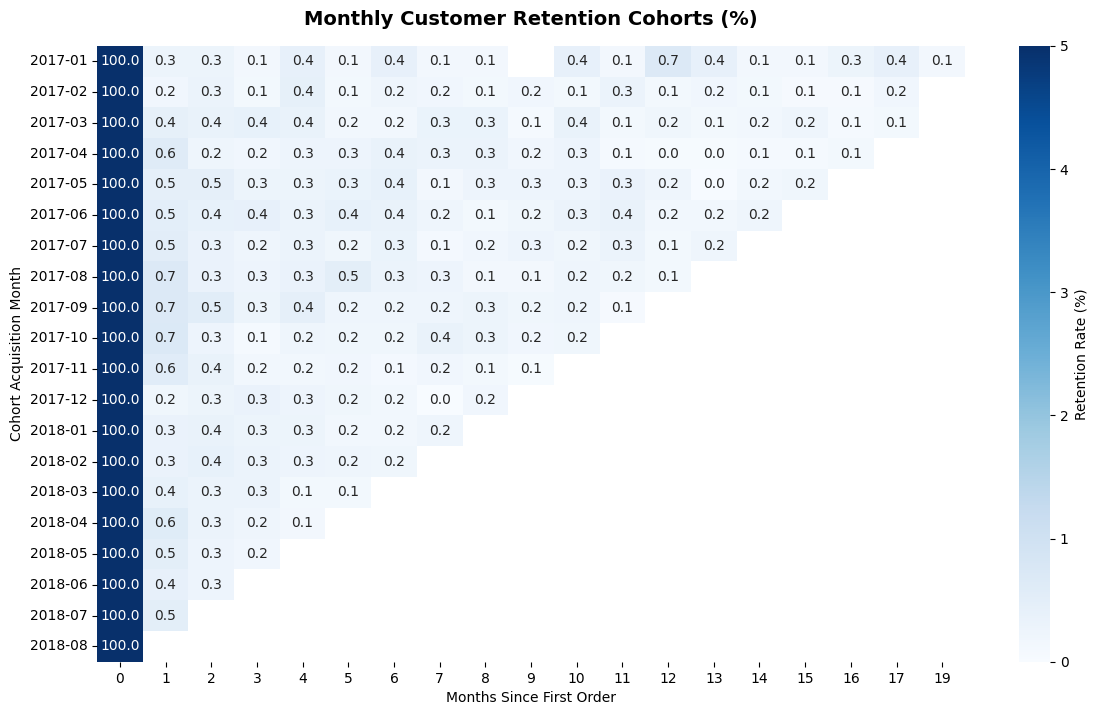

In [20]:
# 1. Pull order date and customer info
query_cohort = """
SELECT 
    c.customer_unique_id,
    o.order_id,
    o.order_purchase_timestamp
FROM fact_orders o
JOIN dim_customers c ON o.customer_id = c.customer_id
WHERE o.order_purchase_timestamp >= '2017-01-01' AND o.order_purchase_timestamp <= '2018-08-31';
"""

df_cohort_raw = pd.read_sql_query(query_cohort, conn)
df_cohort_raw['order_date'] = pd.to_datetime(df_cohort_raw['order_purchase_timestamp'])

# 2. Calculate Order Month & First Purchase (Cohort) Month
df_cohort_raw['order_month'] = df_cohort_raw['order_date'].dt.to_period('M')
df_cohort_raw['cohort_month'] = df_cohort_raw.groupby('customer_unique_id')['order_date'].transform('min').dt.to_period('M')

# 3. Calculate Cohort Index (months passed since acquisition)
def get_month_diff(x):
    return (x['order_month'].dt.year - x['cohort_month'].dt.year) * 12 + (x['order_month'].dt.month - x['cohort_month'].dt.month)

df_cohort_raw['cohort_index'] = get_month_diff(df_cohort_raw)

# 4. Build Cohort Retention Matrix
cohort_data = df_cohort_raw.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

cohort_sizes = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0) * 100.0

# 5. Plot Heatmap
plt.figure(figsize=(14, 8))
plt.title('Monthly Customer Retention Cohorts (%)', fontsize=14, fontweight='bold', pad=15)
sns.heatmap(
    retention_matrix, 
    annot=True, 
    fmt='.1f', 
    cmap='Blues', 
    vmin=0, 
    vmax=5, # Olist retention is typically low, keeping vmax=5 highlights variation
    cbar_kws={'label': 'Retention Rate (%)'}
)
plt.ylabel('Cohort Acquisition Month')
plt.xlabel('Months Since First Order')
plt.show()

In [21]:
import os

# Create folder for processed Power BI files
os.makedirs("data/processed", exist_ok=True)

# 1. Orders Fact Table (delivered orders with date features)
query_fact_orders = """
SELECT 
    o.order_id,
    o.customer_id,
    o.order_status,
    DATE(o.order_purchase_timestamp) AS order_date,
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_year_month,
    i.product_id,
    i.price,
    i.freight_value,
    (i.price + i.freight_value) AS total_item_value
FROM fact_orders o
JOIN fact_order_items i ON o.order_id = i.order_id;
"""
df_powerbi_orders = pd.read_sql_query(query_fact_orders, conn)
df_powerbi_orders.to_csv("data/processed/fact_sales_orders.csv", index=False)

# 2. Customers Dimension with RFM Segment
query_dim_customers = """
SELECT 
    c.customer_id,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state,
    r.Segment AS rfm_segment,
    r.recency AS recency_days,
    r.frequency AS total_orders,
    r.monetary AS total_spent
FROM dim_customers c
LEFT JOIN dim_rfm_segments r ON c.customer_unique_id = r.customer_unique_id;
"""
df_powerbi_customers = pd.read_sql_query(query_dim_customers, conn)
df_powerbi_customers.to_csv("data/processed/dim_customers.csv", index=False)

# 3. Products Dimension (with English Categories)
query_dim_products = """
SELECT 
    product_id,
    product_category_name_english AS product_category
FROM dim_products;
"""
df_powerbi_products = pd.read_sql_query(query_dim_products, conn)
df_powerbi_products.to_csv("data/processed/dim_products.csv", index=False)

print("All 3 Power BI tables exported successfully into 'data/processed/' folder!")

All 3 Power BI tables exported successfully into 'data/processed/' folder!
